# SOD SHOCK-TUBE PROBLEM

$$\frac{\partial \bf{U}}{\partial t}+\bf{A}\frac{\partial \bf{U}}{\partial t}=0$$ 
\
$$(x,t)\in \Omega \times [0,T]$$
\
where,
\
$$\bf{U}=[\rho,u,p]^{T}$$
\
$$\bf{A}=\begin{matrix}
u&\rho&0\\
0&u&\frac{1}{\rho}\\
0&\rho a^{2}&u\\
\end{matrix}$$
\
where $a=\sqrt{\gamma p/\rho}$

## Importing libraries

In [24]:
import numpy as np # numpy
import math  # math
import time  # time
import pandas as pd # pandas

# for residual points generating
from pyDOE import lhs

# Import torch libraries
import torch
from torch import Tensor
import torch.autograd as autograd
import torch.optim as optim
import torch.nn as nn

# matplotlib for ploting
import matplotlib.pyplot as plt

# Saving data files
from numpy import asarray
from numpy import savetxt

## Random Seed Value

In [25]:
torch.set_default_dtype(torch.float)
torch.manual_seed(789)
np.random.seed(789)

## Check for GPU

In [26]:
torch.cuda.empty_cache() # Empty the cache memory
# save the device name of gpu
device=torch.cuda.get_device_name()
print("Original Device Name:",device)


device=torch.device('cuda' if torch.cuda.is_available() else "cpu")
print(device)

Original Device Name: NVIDIA GeForce RTX 3060 Laptop GPU
cuda


## Generating Training data

In [27]:
# Generate data x (position) from 0 to 1 (100 points)
Xdata=np.linspace(0,1,100)[:,None]

# Generate data t (time) from 0 to 0.2 sec (100 points)
Tdata=np.linspace(0,0.2,100)[:,None]

In [28]:
# Generating mesh grid from data x and t

X,T=np.meshgrid(Xdata,Tdata)

## Initial condition

In [29]:
all_xt=np.hstack((X.flatten()[:,None],T.flatten()[:,None]))
IniXT=all_xt[0:100,:]
#print((IniXT.shape[0]))

In [30]:
# Initial density

IniDen_1=[1]*(IniXT.shape[0]//2)
IniDen_1=np.array(IniDen_1)[:,None]
#print(IniDen_1.shape)

IniDen_2=[0.125]*(IniXT.shape[0]//2)
IniDen_2=np.array(IniDen_2)[:,None]
#print(IniDen_2.shape)

In [31]:
# Initial pressure

IniPres_1=[1]*(IniXT.shape[0]//2)
IniPres_1=np.array(IniPres_1)[:,None]
#print(IniPres_1.shape)

IniPres_2=[0.1]*(IniXT.shape[0]//2)
IniPres_2=np.array(IniPres_2)[:,None]
#print(IniPres_2.shape)

In [32]:
# Initial velocity

Inivel_1=[0]*(IniXT.shape[0])
Inivel_1=np.array(Inivel_1)[:,None]
print(Inivel_1.shape)

(100, 1)


In [33]:
# vstack the values for initial condition

IniDen=np.vstack((IniDen_1,IniDen_2))
IniPres=np.vstack((IniPres_1,IniPres_2))
Inivel=Inivel_1

all_RhoPU_Ini=np.hstack((IniDen,IniPres,Inivel))
print(all_RhoPU_Ini.shape)

# Initial Plot
#plt.figure(figsize=(15,15))
#fig,ax=plt.subplots(2,sharex=True)

#ax[0].plot(IniXT[:,[0]],all_RhoPU_Ini[:,[0]])
#ax[0].set_title("Initial Density",fontsize=16)
#ax[1].plot(IniXT[:,[0]],all_RhoPU_Ini[:,[1]])
#ax[1].set_title("Initial Pressure",fontsize=16)
#plt.show()

########
#       IniXT=[x, t]-------->   200*2
#       all_RhoPU=[Rho, P, U]-> 200*3
########

(100, 3)


## Boundary Conidition

In [34]:
# Drichlet boundary condition is present at the boundarys same as the initial condition
#
# BC1
Boundary_1=all_xt[::100,:]
#print(Boundary_1)
B1_Den=[1]*(Boundary_1.shape[0])
B1_Den=np.array(B1_Den)[:,None]

B1_Pres=[1]*(Boundary_1.shape[0])
B1_Pres=np.array(B1_Pres)[:,None]

B1_U=[0]*(Boundary_1.shape[0])
B1_U=np.array(B1_U)[:,None]

all_boundary1=np.hstack((B1_Den,B1_Pres,B1_U))

##################################################

# BC2
Boundary_2=all_xt[99::100,:]
#print(Boundary_2)

B2_Den=[0.125]*(Boundary_2.shape[0])
B2_Den=np.array(B2_Den)[:,None]

B2_Pres=[0.1]*(Boundary_2.shape[0])
B2_Pres=np.array(B2_Pres)[:,None]

B2_U=[0]*(Boundary_2.shape[0])
B2_U=np.array(B2_U)[:,None]

all_boundary2=np.hstack((B2_Den,B2_Pres,B2_U))

all_Boundary=np.vstack((Boundary_1,Boundary_2))

all_RhoPU=np.vstack((all_boundary1,all_boundary2))

###################################################
#plt.figure(figsize=(3,3))
#plt.scatter(all_Boundary[:,[1]],all_RhoPU[:,[1]])
#plt.xlabel("t",fontsize=16)
#plt.ylabel("P",fontsize=16)
#plt.tick_params(axis="x",labelsize=16)
#plt.tick_params(axis="y",labelsize=16)
#plt.show()
###################################################

In [35]:
# Initial and Boundary condition values

BcIc_xt=np.vstack((IniXT,all_Boundary))

# Initial and Boundary condition values
BcIc_RhoPU=np.vstack((all_RhoPU_Ini,all_RhoPU))

## Generate random data inside the domain

In [36]:
Nf=1000 # Number of residual points inside the domain
Nu=200  # Number of training points

# random selection of training points
idx=np.random.choice(BcIc_xt.shape[0],Nu,replace=False)
X_u_train=BcIc_xt[idx,:]
u_train=BcIc_RhoPU[idx,:]


lb=all_xt[0]   #Lower limit
ub=all_xt[-1]  #upper limit

# Residual points
Train_points=lb+(ub-lb)*lhs(2,Nf)

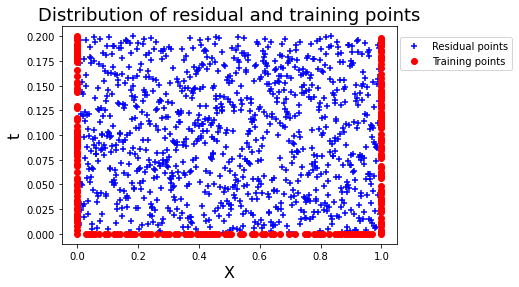

In [37]:
## Ploting the Distribution of residual and training points

plt.scatter(Train_points[:,[0]],Train_points[:,[1]],marker="+",color='b',
            label='Residual points')
plt.scatter(X_u_train[:,[0]],X_u_train[:,[1]],marker="o",color='r',
           label='Training points')
plt.xlabel("X",fontsize=16)
plt.ylabel("t",fontsize=16)
plt.legend(loc=[1.01,0.8])
plt.title("Distribution of residual and training points",fontsize=18)
plt.show()

In [38]:
all_train_data=np.vstack((Train_points,X_u_train))

#savetxt('Train_points',Train_points,delimiter=',')
#savetxt('X_u_train',X_u_train,delimiter=',')

## Convert float to Tensor

In [39]:
X_u_train=torch.from_numpy(X_u_train).float().to(device)
u_train=torch.from_numpy(u_train).float().to(device)
all_train_data=torch.from_numpy(all_train_data).float().to(device)

f_hat=torch.zeros(all_train_data.shape[0],1).to(device)

## PINNs

In [40]:
class shocktube(nn.Module):
    
    def __init__(self,layers):
        
        # Inherentance: taking the function from nn.Module
        super().__init__()
        
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the loss function as Mean square loss function
        self.MSELoss=nn.MSELoss(reduction="mean")
        
        # Generating the Module List
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1]) for i in range(len(layers)-1)])
        
        # Iteration
        self.iter=0
        
        # Defining the Xavier normal for weight and zero as bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=5/3)
            nn.init.zeros_(self.linears[i].bias.data)
            
    # Forward pass function        
    def forward(self,X):
        
        alpha=0.0001
        
        # Check whether the x data is Tensor or not 
        if torch.is_tensor(X)==False:
            X=torch.from_numpy(X).float()
            
         # Converting the Boundary values to torach and adding them to device (min,max)
        ULimit=torch.from_numpy(ub).float().to(device)
        LLimit=torch.from_numpy(lb).float().to(device)
        
        # Feature scale
        X=(X-LLimit)/(ULimit-LLimit)
        
        a=X.float()
        
        # Concatinate 
        Rho_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        P_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        U_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        
        # Forward pass loop upto the second last layer
        for i in range(len(layers)-2):
            z1=self.linears[i](Rho_Pred)
            z2=self.linears[i](P_Pred)
            z3=self.linears[i](U_Pred)
            
            Rho_Pred=self.activation(z1)
            P_Pred=self.activation(z2)
            U_Pred=self.activation(z3)
        
        # Pass the data to the last layer (unit activatin function)
        Rho_Pred=self.linears[-1](Rho_Pred)
        P_Pred=self.linears[-1](P_Pred)
        U_Pred=self.linears[-1](U_Pred)
        
        #print(Rho_Pred)
        
        # +ve
        for i in range(len(Rho_Pred)):
            if Rho_Pred[i,[0]]<=0 :
                Rho_Pred[i,[0]]=alpha
                
        for i in range(len(Rho_Pred)):
            if Rho_Pred[i,[1]]<=0:
                Rho_Pred[i,[1]]=alpha
                
        #for i in range(len(P_Pred)):
        #    if P_Pred[i,[0]]<=0 or  P_Pred[i,[1]]<=0:
        #        P_Pred[i,[0]]=alpha
        #        P_Pred[i,[1]]=alpha
                
        #for i in range(len(U_Pred)):
        #    if U_Pred[i,[0]]<=0 or U_Pred[i,[1]]<=0:
        #        U_Pred[i,[0]]=alpha
        #        U_Pred[i,[1]]=alpha
                
        # a=[Rho,P,U]
        a=torch.cat((Rho_Pred,P_Pred,U_Pred),1)
        
        return a
    
    # Boundary condition loss function
    def lossBC(self,X,Y):
        
        # Forward pass the values (Boundary and Initial values)
        PRED_VAL=self.forward(X)
        
        RHO_P=PRED_VAL[:,[0]] # Predicted Rho
        P_P=PRED_VAL[:,[1]]  # Predicted Pressure
        U_P=PRED_VAL[:,[2]]  # Predicted velocity
        
        loss_Rho=self.MSELoss(RHO_P,Y[:,[0]]) # Loss in Rho
        loss_P=self.MSELoss(P_P,Y[:,[1]])  # Loss in Pressure
        loss_U=self.MSELoss(U_P,Y[:,[2]])  # Loss in velocity
        
        # Sum of BC loss
        BC_Loss=loss_Rho+loss_P+loss_U
        
        return BC_Loss
    
    # PDE Loss function 
    def lossPDE(self,xy_to_train_f):
        # Gamma of air 
        gamma=1.4
        
        g=xy_to_train_f.clone()
        
        g.requires_grad=True
        
        # Forward Pass the data xy_to_train_f
        RhoPU=self.forward(g)
        
        Rho=RhoPU[:,[0]]
        P=RhoPU[:,[1]]
        U=RhoPU[:,[2]]
        
        #print(Rho[1])
        
        # Calculating the Energy
        E=Rho*(0.5*U**2+(P/(gamma-1)*Rho))
        
        # Calculating the gradient of Rho with respect to x and t
        Rho_xt=autograd.grad(Rho,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        Rho_x=Rho_xt[:,[0]]
        Rho_t=Rho_xt[:,[1]]
        
        # Calculating the gradient of Pressure with respect to x and t
        P_xt=autograd.grad(P,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        P_x=P_xt[:,[0]]
        P_t=P_xt[:,[1]]
        
        # Calculating the gradient of velocity with respect to x and t
        U_xt=autograd.grad(U,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        U_x=U_xt[:,[0]]
        U_t=U_xt[:,[1]]
        
        # Calculating the gradient of energy with respect to x and t
        E_xt=autograd.grad(E,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        E_x=E_xt[:,[0]]
        E_t=E_xt[:,[1]]
        
        # Thre equation fof conservation of mass momentum and energy
        f1=Rho_t + U*(Rho_x) + Rho*U_x 
        f2=Rho*(U_t + U*U_x) + P_x
        f3=P_t + gamma*P*U_x + U*P_x
        
        # MSE Loss function calculation
        LossF1=self.MSELoss(f1,f_hat)
        LossF2=self.MSELoss(f2,f_hat)
        LossF3=self.MSELoss(f3,f_hat)
        
        # Total PDE Loss
        LossPDE=LossF1+LossF2+LossF3
        
        return LossPDE
    
    def Entropy(self,xy_to_train_f):
         # Gamma of air 
        gamma=1.4
        
        g=xy_to_train_f.clone()
        
        g.requires_grad=True
        
        # Forward Pass the data xy_to_train_f
        RhoPU=self.forward(g)
        
        Rho=RhoPU[:,[0]]
        P=RhoPU[:,[1]]
        U=RhoPU[:,[2]]
        
        # Entropy
        for i in range(len(Rho)):
            Rho[i,[0]]=Rho[i,[0]]**gamma
        
        #print(Rho[1])
        
        s=torch.log10(P/Rho)
        
        eta=-(Rho*s)/(gamma-1)
        phi=-(Rho*(U)*(s))/(gamma-1)
        
        #print("eta:",eta.shape)
        #print("phi:",phi.shape)
        
        eta_xt=autograd.grad(eta,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        eta_x=eta_xt[:,[0]]
        eta_t=eta_xt[:,[1]]
        
        
        phi_xt=autograd.grad(phi,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        phi_x=phi_xt[:,[0]]
        phi_t=phi_xt[:,[1]]
        
        f=eta_t+phi_x+0.001
        
        lossf=self.MSELoss(f,f_hat)
        
        
        return lossf
    
    # Total loss function 
    def loss(self,X,Y,xy_to_train_f):
        
        # Callling the boundary loss function 
        loss1=self.lossBC(X,Y)
        # Calling the pde loss function 
        loss2=self.lossPDE(xy_to_train_f)
        
        loss3=self.Entropy(xy_to_train_f)
        
        #Total loss function which is sum of both the loss function
        Total_Loss=loss2*0.1 + loss1*10 + loss3
        total_loss=loss2+loss1 + loss3
        
        # Saving the Data
        #file1=open('BC_LOSS.txt','a')
        #file1.write(str(loss1.item())+'\n')
        #file1.close()
        
        #file1=open('PDE_LOSS.txt','a')
        #file1.write(str(loss2.item())+'\n')
        #file1.close()
        
        #file3=open('TOTAL_LOSS_W.txt','a')
        #file3.write(str(Total_Loss.item())+'\n')
        #file3.close()
        
        #file4=open('TOTAL_LOSS.txt','a')
        #file4.write(str(total_loss.item())+'\n')
        #file4.close()
        
        # Return the total loss value
        return Total_Loss
    
    # Closure function
    def closure(self):
        
        # Initialization the gradient as zero
        optimizer.zero_grad()
        
        # Calling the loss function which further calls the loss BC and Loss PDE
        loss=self.loss(X_u_train,u_train,all_train_data)
        
        # Backprop
        loss.backward()
        
        # Iteration 
        self.iter+=1
        
        # Print the loss at every 100 iterations
        if self.iter%100==0:
            print(loss)
        
        return loss
    
    # Test function 
    def Test(self,Test_data):
        
        # Forward pass the test_data values
        Rho_P_U=self.forward(Test_data)
        
        # Taking the results into the cpu from the gpu
        Rho_P_U=Rho_P_U.detach().cpu().numpy()
        
        #
        Rho_Pred=Rho_P_U[:,[0]]
        P_Pred=Rho_P_U[:,[1]]
        U_Pred=Rho_P_U[:,[2]]
        
        # Predict the dependent parameters=[Density, Pressure, Velocity]
        return [Rho_Pred,P_Pred,U_Pred]

In [41]:
layers=[2,20,20,20,20,3] # No of neurons with each layer

ST=shocktube(layers) # Object of the class
ST.to(device)  # Passing the object of the device

params=list(ST.parameters()) # 

# We can use multiple optimization 
# Here we have considered only one optimizer (LBFGS).
optimizer=optim.LBFGS(ST.parameters(),lr=0.1,max_iter=10000,
                     tolerance_grad=1e-10,max_eval=None,tolerance_change=1e-8,
                      history_size=1000,line_search_fn="strong_wolfe")

#Training Time for the optimization
start_time1=time.time()
optimizer.step(ST.closure)
Training_Time1=time.time()-start_time1

# optimizer2=optim.LBFGS(ST.parameters(),lr=0.001,max_iter=10000,
#                       tolerance_grad=1e-20,max_eval=None,tolerance_change=1e-20,
#                        history_size=1000,line_search_fn="strong_wolfe")
# start_time2=time.time()
# optimizer2.step(ST.closure)
# Training_Time2=time.time()-start_time2

print("Training Time:",Training_Time1)#+Training_Time2)

tensor(0.4095, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.2186, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.1215, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0824, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0628, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0531, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0446, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0388, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0339, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0306, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0261, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0225, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0186, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0170, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0154, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0138, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0128, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0114, device='cuda:0', grad_fn=<AddBack

---
---

## Prediction

### At Time =0.2s

In [87]:
Test_data_0_101=all_xt[7500:7600,:]
Test_data=Test_data_0_101

# Converting the value from list to tensor
Test_data=torch.from_numpy(Test_data).float().to(device)

print(Test_data.shape)

tensor([[0.0000, 0.1515],
        [0.0101, 0.1515],
        [0.0202, 0.1515],
        [0.0303, 0.1515],
        [0.0404, 0.1515],
        [0.0505, 0.1515],
        [0.0606, 0.1515],
        [0.0707, 0.1515],
        [0.0808, 0.1515],
        [0.0909, 0.1515],
        [0.1010, 0.1515],
        [0.1111, 0.1515],
        [0.1212, 0.1515],
        [0.1313, 0.1515],
        [0.1414, 0.1515],
        [0.1515, 0.1515],
        [0.1616, 0.1515],
        [0.1717, 0.1515],
        [0.1818, 0.1515],
        [0.1919, 0.1515],
        [0.2020, 0.1515],
        [0.2121, 0.1515],
        [0.2222, 0.1515],
        [0.2323, 0.1515],
        [0.2424, 0.1515],
        [0.2525, 0.1515],
        [0.2626, 0.1515],
        [0.2727, 0.1515],
        [0.2828, 0.1515],
        [0.2929, 0.1515],
        [0.3030, 0.1515],
        [0.3131, 0.1515],
        [0.3232, 0.1515],
        [0.3333, 0.1515],
        [0.3434, 0.1515],
        [0.3535, 0.1515],
        [0.3636, 0.1515],
        [0.3737, 0.1515],
        [0.3

### Predicted

In [88]:
# Predicting the results.

[DENSITY_Pred,Pressure_Pred,Velocity_Pred]=ST.Test(Test_data)

### Exact Solution

In [89]:
cfd_data=pd.read_csv('D:\\SOD_SHOCK_TUBE\\CASE1\\DATA_SHOCK_TUBE.csv')
#print(cfd_data.columns)
cfd_data=cfd_data.to_numpy()

t_cor_cfd=cfd_data[:,[0]]
x_cor_cfd=cfd_data[:,[1]]
pressure_cfd=cfd_data[:,[3]]
density_cfd=cfd_data[:,[4]]
velocity_cfd=cfd_data[:,[5]]

train_cfd_data=np.hstack((x_cor_cfd,t_cor_cfd,pressure_cfd,density_cfd,velocity_cfd))
#print(train_cfd_data[238::239])

Exact_solution=train_cfd_data[7170:7409]

print(Exact_solution)

presrhovel=Exact_solution[:,2:]
x_val=Exact_solution[:,0]
Pressure=presrhovel[:,0]
Density=presrhovel[:,1]
Velocity=presrhovel[:,2]

[[0.00e+00 1.50e-01 1.00e+00 1.00e+00 4.91e-16]
 [3.39e-03 1.50e-01 1.00e+00 1.00e+00 5.03e-16]
 [7.11e-03 1.50e-01 1.00e+00 1.00e+00 6.16e-16]
 ...
 [9.93e-01 1.50e-01 1.00e-01 1.25e-01 7.24e-16]
 [9.97e-01 1.50e-01 1.00e-01 1.25e-01 4.62e-16]
 [1.00e+00 1.50e-01 1.00e-01 1.25e-01 2.11e-16]]


### Ploting

[]

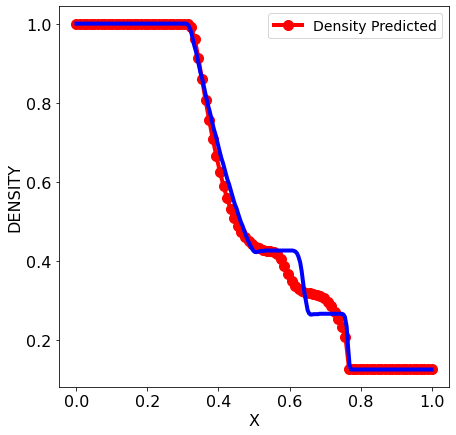

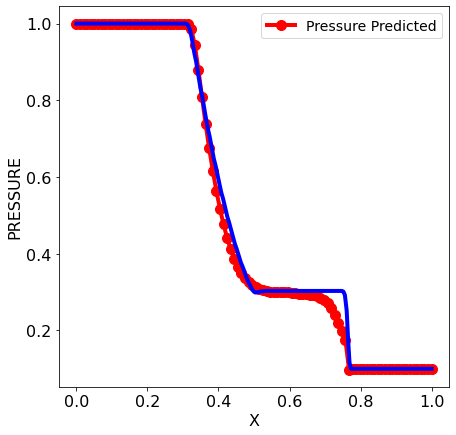

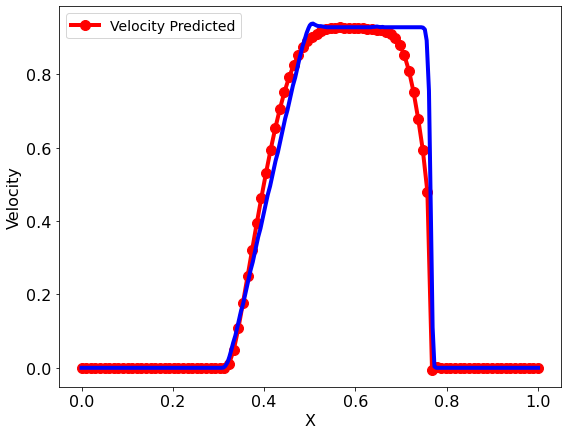

In [90]:
# Ploting
# Density Plot
#print(Test_data_0_101[:,:])
plt.figure(figsize=(7,7))
plt.plot(Test_data_0_101[:,[0]],DENSITY_Pred,linewidth=4,color="r",marker='o',markersize=10,label="Density Predicted")
plt.plot(x_val,Density,linewidth=4,color='b')
plt.legend(fontsize=14)
plt.xlabel("X",fontsize=16)
plt.ylabel("DENSITY",fontsize=16)
plt.tick_params(axis="x",labelsize=16)
plt.tick_params(axis="y",labelsize=16)
plt.plot()
savetxt('Test_data_Try_015.csv',Test_data_0_101[:,[0]],delimiter=',')
savetxt('DENSITY_Pred_Try_015.csv',DENSITY_Pred,delimiter=',')
##----------------##----------------##---------------------##-----------------##

# Pressure Plot
plt.figure(figsize=(7,7))
plt.plot(Test_data_0_101[:,[0]],Pressure_Pred,linewidth=4,color="r",marker='o',markersize=10,label="Pressure Predicted")
plt.plot(x_val,Pressure,linewidth=4,color='b')
plt.legend(fontsize=14)
plt.xlabel("X",fontsize=16)
plt.ylabel("PRESSURE",fontsize=16)
plt.tick_params(axis="x",labelsize=16)
plt.tick_params(axis="y",labelsize=16)
plt.plot()

savetxt('Pressure_Pred_Try_015.csv',Pressure_Pred,delimiter=',')

##------------------##-----------------------##---------------------##--------------------##

# Velocity Plot
plt.figure(figsize=(9,7))
plt.plot(Test_data_0_101[:,[0]],Velocity_Pred,linewidth=4,color="r",marker='o',markersize=10,label="Velocity Predicted")
plt.plot(x_val,Velocity,linewidth=4,color='b')
plt.legend(fontsize=14)
plt.xlabel("X",fontsize=16)
plt.ylabel("Velocity",fontsize=16)
plt.tick_params(axis="x",labelsize=16)
plt.tick_params(axis="y",labelsize=16)
plt.plot()

savetxt('Velocity_Pred_Try_0.15.csv',Velocity_Pred,delimiter=',')

---
---

In [91]:
savetxt('Exact_Density_015.csv',Density,delimiter=',')
savetxt('Exact_Pressure_015.csv',Pressure,delimiter=',')
savetxt('Exact_Velocity_015.csv',Velocity,delimiter=',')
savetxt('XT_EXACT_015.csv',x_val,delimiter=',')
